# Simulation of Relaxation Dynamics and Time-Resolved Spectra for a Coupled Doublet–Triplet System


This notebook demonstrates the construction of a relaxation model for a spin system consisting of a doublet (S=½) and a triplet (S=1) with exchange coupling.  
We will:

1. Build the spin samples (doublet, triplet, and their coupled complex).
2. Define relaxation pathways (population decay, Zeeman thermalization, dephasing).
3. Compute stationary (CW) spectra.
4. Simulate time‑resolved spectra for different exchange coupling strengths.
5. Visualize and compare the results for different computation methods

We strongly recommend that you first review Example 1, then Example 5, and then begin working with this notebook.


\
\
\
\
\
\
For any questions, please contact Arkady Samsonenko via: \
Telegram: @Arkady_Samsonenko \
Email: a.samsonenko.tomo.nsc.ru\
\
\
The last notebook update: 2026.11.14

In [1]:
# Import necessary libraries
%load_ext autoreload
%autoreload 2

import sys
import os
import math

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', "..")))

# Import Mars library components
import mars
from mars import spin_model, spectra_manager, mesher, constants
from mars import utils
from mars import population

# # Let's import some useful functions for plotting simulation results over time.
from mars import visualization

In [2]:
dtype = torch.float64
device = torch.device("cpu")

# Experimental parameters
freq_res = 9.8 * 1e9          # 9.8 GHz microwave frequency
temperature = torch.tensor(100.0, dtype=dtype, device=device)   # Temperature in Kelvin

# 1. Sample Construction


We define a function get_samples that creates three SolidSample objects:

1) Doublet (S=1/2) – has an anisotropic g‑tensor.

2) Triplet (S=1) – has a zero‑field splitting (ZFS) interaction.

3) Complex – a coupled system of doublet and triplet with an isotropic exchange interaction.



> Note: In this notebook, the term *exchange interaction* refers to the Hamiltonian term
>
  $$
  \mathcal{H}_{\mathrm{ex}} = J\,S_1 S_2.
  $$
>
> In the original manuscript, the corresponding term is written as
>
  $$
  \mathcal{H}_{\mathrm{ex}} = -2J\,S_1 S_2.
  $$
>
> Thus, the notebook convention differs from the manuscript convention by a factor of $-2$.

In [3]:
# Let's start from the sample creation
def get_samples(exchange_value: float, D=500e6, E=100e6,
                g_doublet=(2.02, 2.04, 2.25)):
    """
    Create the doublet, triplet, and coupled complex samples.

    :param exchange_value: Exchange coupling constant (in Hz) between doublet and triplet.
    :param D: Triplet axial ZFS in Hz.
    :param E: Triplet rhombic ZFS in Hz.
    :param g_doublet: Principal doublet g values.
    :return: Doublet (S=1/2) sample with anisotropic g-tensor, Triplet (S=1) sample with ZFS, Coupled doublet–triplet system with the given exchange interaction.
    """
    g_tensor_triplet = spin_model.Interaction([2.000, 2.002, 2.004], dtype=dtype, device=device)
    zfs_interaction = spin_model.DEInteraction([D, E], dtype=dtype, device=device)  # ZFS parameters in Hz

    base_spin_system = spin_model.SpinSystem(
        electrons=[1.0],  # S=1 triplet
        g_tensors=[g_tensor_triplet],
        electron_electron=[(0, 0, zfs_interaction)]
    )

    triplet = spin_model.SolidSample(
        base_spin_system=base_spin_system,
        ham_strain=0.0,
        gauss=0.002,
        lorentz=0.0015,
        device=device,
        dtype=dtype
    )
    
    # Doublet (S=1/2) – anisotropic g
    g_tensor_doublet = spin_model.Interaction(g_doublet, dtype=dtype, device=device)
    base_spin_system = spin_model.SpinSystem(
        electrons=[0.5],  # S=0.5
        g_tensors=[g_tensor_doublet],
    )
    doublet = spin_model.SolidSample(
        base_spin_system=base_spin_system,
        ham_strain=0.0,
        gauss=0.002,
        lorentz=0.002,
        device=device,
        dtype=dtype
    )
    
    # Complex coupled system: doublet + triplet with exchange
    exchange_interaction = spin_model.Interaction(exchange_value, dtype=dtype, device=device)   # Here we define exchange interaction as JS1S2. In the article this is -2JS1S2
    base_spin_system = spin_model.SpinSystem(
        electrons=[0.5, 1.0],  # S=0.5 triplet
        g_tensors=[g_tensor_doublet, g_tensor_triplet],
        electron_electron=[(1, 1, zfs_interaction), (0, 1, exchange_interaction)],
    )

    sample_complex = spin_model.SolidSample(
        base_spin_system=base_spin_system,
        ham_strain=0.0,
        gauss=0.002,
        lorentz=0.002,
        device=device,
        dtype=dtype
    )
    return doublet, triplet, sample_complex

# 2.Relaxation Contexts

We define a function get_contexts that builds the population.Context objects for each subsystem and for the coupled system.
The contexts describe:

1) Doublet: initial populations (Boltzmann) and a rate for spin‑lattice relaxation (thermal rates between its two Zeeman levels).

2) Triplet: initial population in one sublevel (in the xyz basis), rate among triplet sublevels

3) Complex: combines the triplet and doublet contexts using mars.multiply (tensor product of the two density matrices) and adds a dephasing term.

In [4]:
def get_contexts(temperature, doublet, triplet, sample_complex,
                 wD=1e4, wT=1e3, gamma_phi=1e6):
    """
    Build relaxation contexts for the doublet, triplet, and coupled system.

    :param temperature: Temperature used for Boltzmann populations.
    :param doublet: Doublet sample.
    :param triplet: Triplet sample.
    :param sample_complex: Coupled sample.
    :param wD: Doublet thermal transition rate in s^-1.
    :param wT: Triplet thermal transition rate in s^-1.
    :param gamma_phi: Eigenbasis pure-dephasing rate in s^-1.
    :return: Doublet context with thermal rates,
    Triplet context with initial population and thermal rates,
    Coupled context (product of triplet and doublet) with dephasing.
    """
    
    # Compute Boltzmann populations for doublet
    fields = torch.tensor([0.34], dtype=dtype)
    F, _, _, Gz = doublet.get_hamiltonian_terms()
    H = F + Gz * fields
    H  = H.unsqueeze(-3)
    energies, full_system_vectors = torch.linalg.eigh(H)

    populations_doublet = torch.softmax(
        constants.unit_converter(-energies, "Hz_to_K") / temperature, dim=-1
                                )[0, 0]
    
    # Triplet context in xyz basis with initial population in the third sublevel
    context_triplet_xyz = population.Context(
        basis="xyz",
        sample=triplet,
        init_populations=[0.0, 0.0, 1.0],
        decay_rates=[0.0, 0.0, 0.0],
        dtype=dtype,
    )

    # Triplet thermalisation among Zeeman sublevels
    context_triplet_zeeman = population.Context(
        basis="zeeman",
        sample=triplet,
        thermal_rates=torch.tensor([[-0.0, wT, 0.0],
                                     [wT, -0.0, wT],
                                     [0.0, wT, -0.0]], dtype=dtype),
        dtype=dtype,
    )

    # Doublet context with initial thermal populations and thermal rates
    context_doublet = population.Context(
        basis="zeeman",
        sample=doublet,
        init_populations=populations_doublet,
        thermal_rates=torch.tensor([[-0.0, wD],
                                     [wD, -0.0]], dtype=dtype),
        dtype=dtype
    )

    # Dephasing for the coupled system
    context_dephasing = population.Context(
        basis="eigen",
        sample=sample_complex,
        dephasing=[gamma_phi for _ in range(6)],
        dtype=dtype
    )

    # Coupled context: tensor product of triplet (xyz + zeeman) and doublet contexts
    context_triplet_total = context_triplet_xyz + context_triplet_zeeman
    context_complex = mars.multiply((context_doublet, context_triplet_total)) + context_dephasing

    return context_doublet, context_triplet_total, context_complex

In [5]:
doublet, triplet, sample_complex = get_samples(300e6)
context_doublet, context_triplet, context_complex = get_contexts(temperature, doublet, triplet, sample_complex)

# 3. Polarized and Steady-State (CW) Spectra

We compute spin-polarized and equilibrium spectra absorption spectra for the doublet, triplet, and coupled system using both the direct Hamiltonian and the secular approximation.
This allows us to see the effect of the secular approximation on the stationary spectrum.

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spin_model.py:3232: UserWarning: MaRs secular approximation may be inaccurate (full H = F + B*Gz: 0.0537 > 0.05). F_ratio=0, Gz_ratio=0.0537. This operator-norm test does not guarantee spectral or relaxation accuracy.
  self._check_secularity(full, secular, field=0.3)


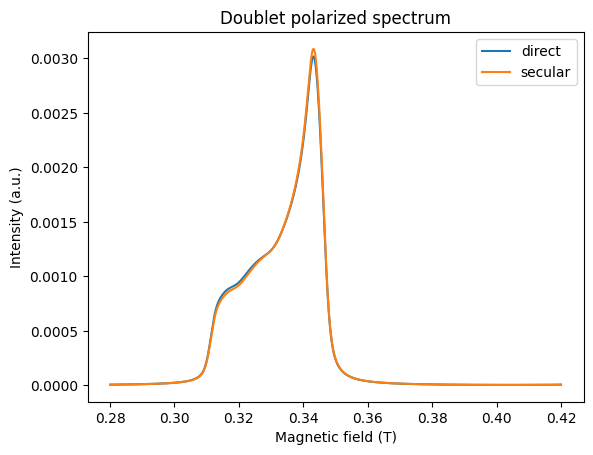

In [6]:
# Field sweep for stationary spectra
fields = torch.linspace(0.28, 0.42, 1000, dtype=dtype, device=device)
normalization = 6e4

# Doublet
polarized = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=doublet,
    harmonic=0,
    context=context_doublet,
    temperature=temperature,
    device=device,
    dtype=dtype
)
out = polarized(doublet, fields)

polarized_sec = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=doublet,
    harmonic=0,
    context=context_doublet,
    temperature=temperature,
    hamiltonian_mode="secular",
    device=device,
    dtype=dtype
)
out_sec = polarized_sec(doublet, fields)

plt.figure()
plt.plot(fields.cpu().numpy(), out.cpu().numpy() / normalization, label="direct")
plt.plot(fields.cpu().numpy(), out_sec.cpu().numpy() / normalization, label="secular")
plt.legend()
plt.title("Doublet polarized spectrum")
plt.xlabel("Magnetic field (T)")
plt.ylabel("Intensity (a.u.)")
plt.show()

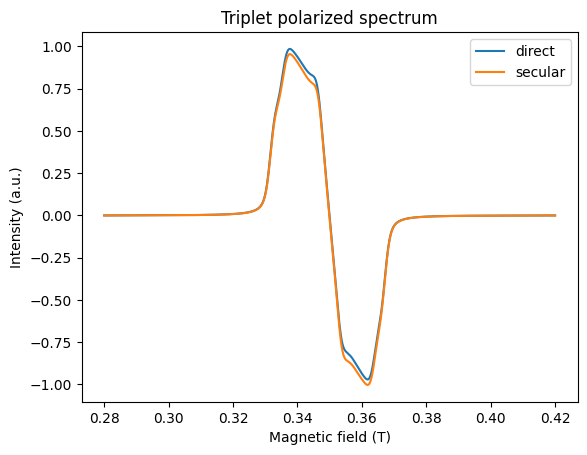

In [7]:
# Triplet
polarized = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=triplet,
    harmonic=0,
    context=context_triplet,
    temperature=temperature,
    device=device,
    dtype=dtype
)
out = polarized(triplet, fields)

polarized_sec = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=triplet,
    harmonic=0,
    context=context_triplet,
    temperature=temperature,
    hamiltonian_mode="secular",
    device=device,
    dtype=dtype
)
out_sec = polarized_sec(triplet, fields)

plt.figure()
plt.plot(fields.cpu().numpy(), out.cpu().numpy() / normalization, label="direct")
plt.plot(fields.cpu().numpy(), out_sec.cpu().numpy() / normalization, label="secular")
plt.legend()
plt.title("Triplet polarized spectrum")
plt.xlabel("Magnetic field (T)")
plt.ylabel("Intensity (a.u.)")
plt.show()

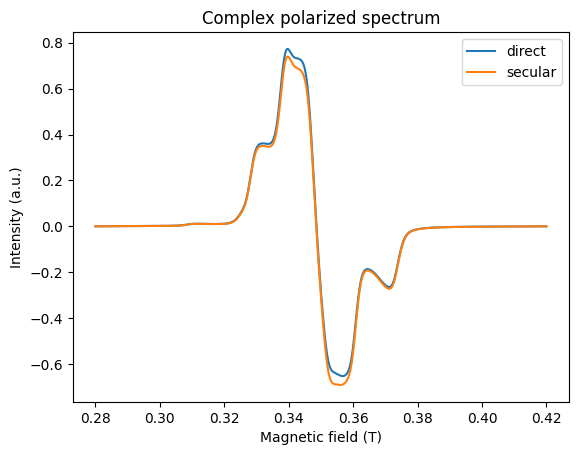

In [8]:
# Complex
polarized = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=sample_complex,
    harmonic=0,
    context=context_complex,
    temperature=temperature,
    device=device,
    dtype=dtype
)
out = polarized(sample_complex, fields)

polarized_sec = spectra_manager.StationarySpectra(
    freq=freq_res,
    sample=sample_complex,
    harmonic=0,
    context=context_complex,
    temperature=temperature,
    hamiltonian_mode="secular",
    device=device,
    dtype=dtype
)
out_sec = polarized_sec(sample_complex, fields)

plt.figure()
plt.plot(fields.cpu().numpy(), out.cpu().numpy() / normalization, label="direct")
plt.plot(fields.cpu().numpy(), out_sec.cpu().numpy() / normalization, label="secular")
plt.legend()
plt.title("Complex polarized spectrum")
plt.xlabel("Magnetic field (T)")
plt.ylabel("Intensity (a.u.)")
plt.show()

It is noticed, that for the high exchange constant the secular approximation fails to reproduce the correct polarized spectrum

# 4. Time‑Resolved Spectra Simulation

We now set up functions to create time‑resolved spectrum calculators and to run simulations.

In [9]:
def get_creators(doublet, triplet, sample_complex):
    """
    Create time‑resolved spectrum calculators for different methods.

    :param doublet: The spin samples.
    :param triplet: The spin samples.
    :param sample_complex: The spin samples.
    :return: List of dict, each containing 'name' (str) and 'instance' (a spectrum manager object).
    """
    harmonic = 0
    fields = torch.linspace(0.28, 0.42, 1000, dtype=dtype, device=device)
    context_doublet, context_triplet, context_complex  = get_contexts(temperature, doublet, triplet, sample_complex)
    creators = [
        {
            "name": "Coupled",
            "instance": spectra_manager.CoupledTimeSpectra(
                freq=freq_res,
                sample=sample_complex,
                harmonic=harmonic,
                context=context_complex,
                temperature=temperature,
                hamiltonian_mode="direct",
                device=device,
                dtype=dtype
            )
        },
        {
            "name": "Density (RWA)",
            "instance": spectra_manager.DensityTimeSpectra(
                freq=freq_res,
                populator="rwa",
                sample=sample_complex,
                harmonic=harmonic,
                context=context_complex,
                temperature=temperature,
                device=device,
                dtype=dtype
            )
        },
        {
            "name": "Density (Propagator)",
            "instance": spectra_manager.DensityTimeSpectra(
                freq=freq_res,
                populator="propagator",
                sample=sample_complex,
                harmonic=harmonic,
                context=context_complex,
                temperature=temperature,
                hamiltonian_mode="direct",
                device=device,
                dtype=dtype
            )
        }
    ]
    return creators

In [17]:
def run_simulation(creators, doublet, triplet, sample_complex, tot_points):
    """
    Run time‑resolved simulations for all creators and normalise spectra.

    :param creators: List of creator dictionaries as returned by get_creators.
    :param doublet: Spin samples.
    :param triplet: Spin samples.
    :param sample_complex: Spin samples.
    :param tot_points: Number of time points.
    :param limit: Maximum time (seconds).
    :return: List of dict, each containing 'name' and a 'long' dict with 'time' and 'spectrum'.
    """
    fields = torch.linspace(0.28, 0.42, 1000, dtype=dtype, device=device)
    time_long = torch.linspace(0.0, 100 * 1e-6, tot_points, dtype=dtype, device=device)
    time_short = torch.linspace(0.0, 1 * 1e-6, tot_points, dtype=dtype, device=device)

    results = []

    print("Running simulations...")
    for creator_data in creators:
        creator = creator_data["instance"]
        name = creator_data["name"]
        print(f"Simulating {name}...")
        spec_long = creator(sample_complex, fields, time_long)
        spec_short = creator(sample_complex, fields, time_short)
        results.append({
            "name": name,
            "long": {"time": time_long, "spectrum": spec_long},
            "short": {"time": time_short, "spectrum": spec_short}

        })

    # Normalise to the intensity at t = 10 µs
    print("Normalizing spectra...")
    target_norm_time = 10e-6
    for res in results:
        time = res["long"]["time"]
        spec = res["long"]["spectrum"]
        idx_norm = torch.argmin(torch.abs(time - target_norm_time)).item()
        max_val = torch.max(torch.abs(spec[idx_norm, :]))
        for term in ["short", "long"]:
            time = res[term]["time"]
            spec = res[term]["spectrum"]
            if max_val < 1e-12:
                max_val = 1.0
            res[term]["spectrum"] = spec / max_val
            print(f"{res['name']}: Normalized by factor {max_val:.4e} at t=10 us")
    return results

# 5. Exchange‑Coupling Dependence

We now sweep over three exchange coupling values and simulate the time‑resolved spectra for a longer time window (0‑100 µs).
This allows us to see how the the relaxation and spectra differ depending on the computation methon and the connection between spin centers

In [20]:
J_values = [1e6, 50e6, 300e6]
results = []
for J in J_values:
    doublet, triplet, sample_complex = get_samples(J)
    creators = get_creators(doublet, triplet, sample_complex)
    res = run_simulation(creators, doublet, triplet, sample_complex, 800)
    results.append(res)

Running simulations...
Simulating Coupled...
Simulating Density (RWA)...
Simulating Density (Propagator)...
Normalizing spectra...
Coupled: Normalized by factor 5.7561e+04 at t=10 us
Coupled: Normalized by factor 5.7561e+04 at t=10 us
Density (RWA): Normalized by factor 1.1054e+02 at t=10 us
Density (RWA): Normalized by factor 1.1054e+02 at t=10 us
Density (Propagator): Normalized by factor 4.5083e+03 at t=10 us
Density (Propagator): Normalized by factor 4.5083e+03 at t=10 us
Running simulations...
Simulating Coupled...
Simulating Density (RWA)...
Simulating Density (Propagator)...
Normalizing spectra...
Coupled: Normalized by factor 5.2909e+04 at t=10 us
Coupled: Normalized by factor 5.2909e+04 at t=10 us
Density (RWA): Normalized by factor 1.0582e+02 at t=10 us
Density (RWA): Normalized by factor 1.0582e+02 at t=10 us
Density (Propagator): Normalized by factor 4.0433e+03 at t=10 us
Density (Propagator): Normalized by factor 4.0433e+03 at t=10 us
Running simulations...
Simulating Coup

### 5.1 Visualisation of 2D spectra for different J

We can plot the 2D spectra for one of the methods (e.g., "Density (Propagator)") and for each J value.

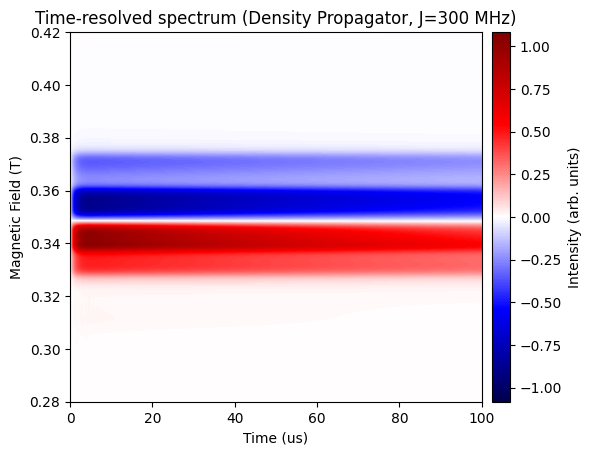

In [87]:
# Example: plot for the last J value (300 MHz) using the propagator method
result = results[-1][2]  # index 2 = Density (Propagator)

# Long time window
spectrum = result["long"]["spectrum"]
time = result["long"]["time"]

visualization.plot_2d_timeresolved(
    fields,
    time,
    spectrum,
    time_unit="us"
)

plt.title("Time-resolved spectrum (Density Propagator, J=300 MHz)")
plt.show()

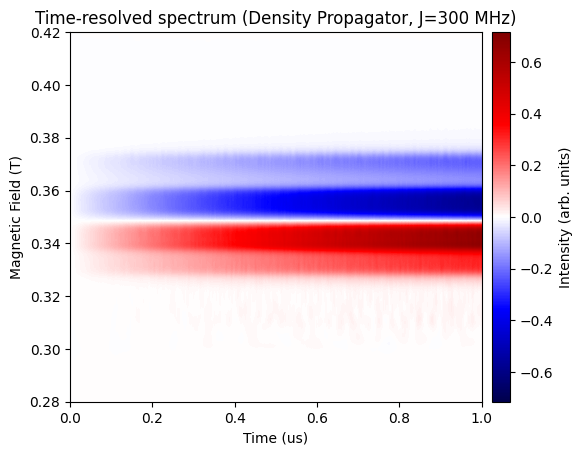

In [88]:
### And short time window
spectrum = result["short"]["spectrum"]
time = result["short"]["time"]

visualization.plot_2d_timeresolved(
    fields,
    time,
    spectrum,
    time_unit="us"
)

plt.title("Time-resolved spectrum (Density Propagator, J=300 MHz)")
plt.show()

It should be noted that a noisy signal in a region where the spectrum is near zero can be attributed to various physical processes,
including incomplete averaging of quantum beats (given that all parameters are anisotropic).

It is highly unlikely that we will see it in the experiment, due to the spectrometer actual resolution.

### 5.2 Field slices at different times

To compare the different methods and J values, we extract slices at two time points (0.5 µs - beggining and 100 µs - long relaxation) and plot the field dependence.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


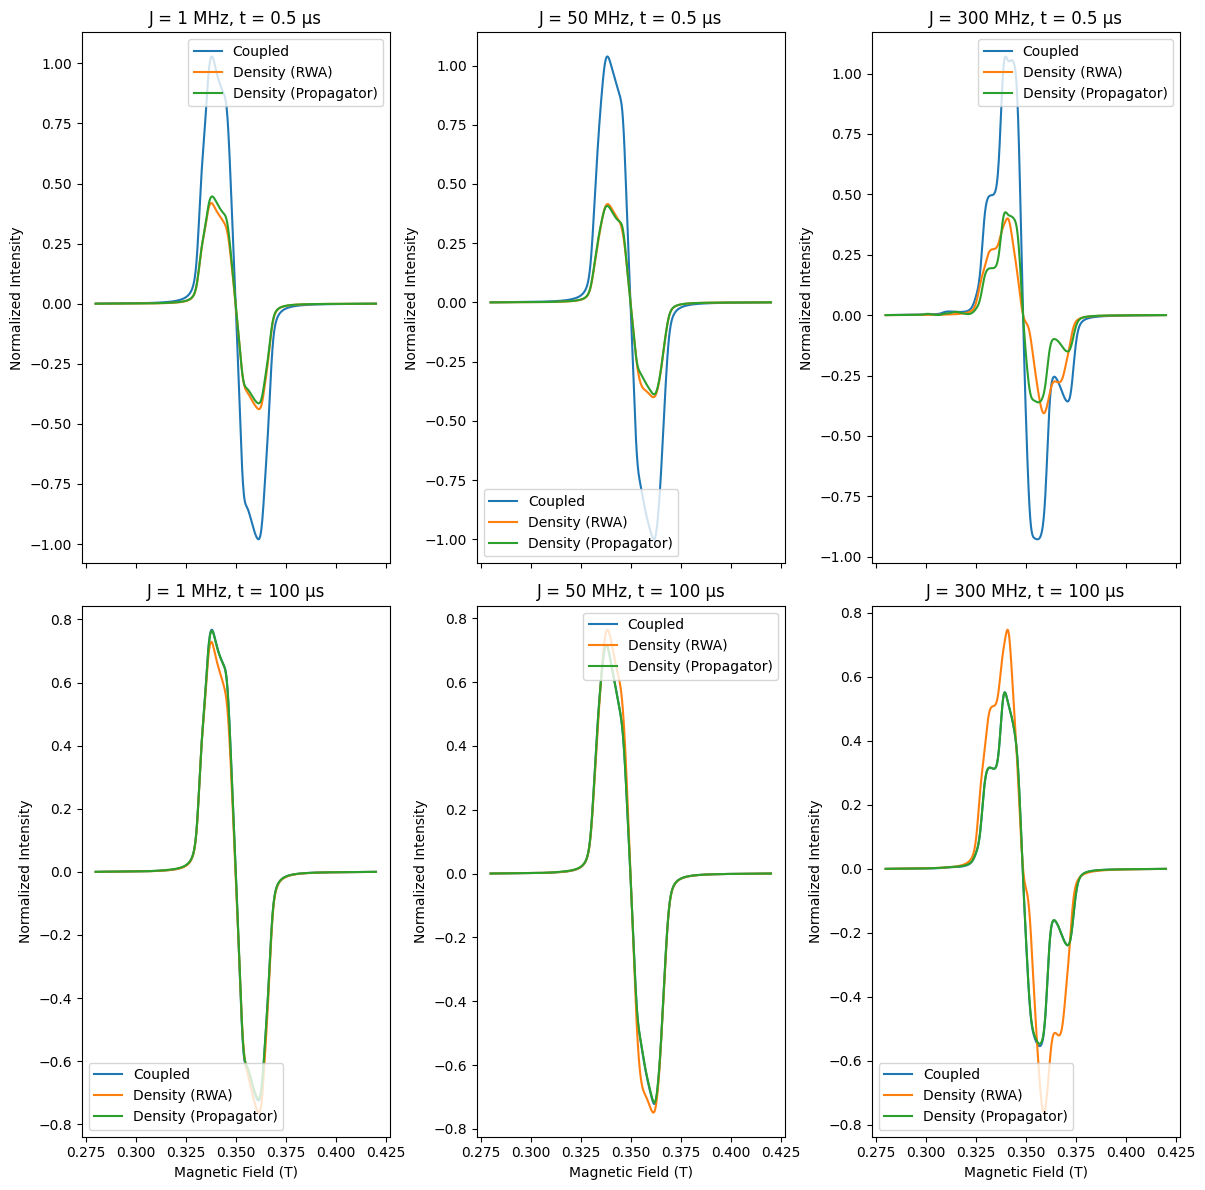

In [86]:
slice_times = [0.5e-6, 100e-6]
slice_labels = ["0.5 µs", "100 µs"]

fig2, axes = plt.subplots(2, 3, figsize=(12, 12), sharex=True)
fields_cpu = fields.cpu().numpy()

for i, result in enumerate(results):          # loop over J values
    for j, (t_target, t_label) in enumerate(zip(slice_times, slice_labels)):
        ax = axes[j][i]
        ax.set_title(f"J = {J_values[i]/1e6:.0f} MHz, t = {t_label}")
        ax.set_ylabel("Normalized Intensity")
        if j == 1:
            ax.set_xlabel("Magnetic Field (T)")

        # Plot all three methods
        for spec_num, res in enumerate(result):
            t_arr = res["long"]["time"]
            spec_arr = res["long"]["spectrum"]
            idx = torch.argmin(torch.abs(t_arr - t_target)).item()
            slice_data = spec_arr[idx, :].cpu().numpy()
            ax.plot(fields_cpu, slice_data, label=res["name"])

        ax.legend(loc='best')

plt.tight_layout()
plt.savefig("cross_section.eps")
plt.show()

1) The coupled spectrum does not account for the T2 relaxation time required to establish the transverse magnetization.

2) In the long-relaxation regime, the coupled and propagator methods are in close agreement.

3) The RWA remains accurate even for J = 50 MHz.


## 6. Nonsecular Relaxation with One Additional Rate Parameter

The preceding calculations show only small differences between the kinetic-rate and Liouvillian propagator methods after the initial buildup of transverse magnetization. In this section, we construct an example in which the nonsecular relaxation terms neglected by the kinetic approximation have a more pronounced effect on the subsequent spectral evolution.

### 6.1. Hamiltonian and Choice of Parameters

We first modify the Hamiltonian parameters to bring the triplet and doublet transition frequencies closer together. The modified model is defined by the following parameters:

| Parameter | Original model | Near-resonant model |
|---|---|---|
| $D$ | $500$ MHz | $0.1$ MHz |
| $E$ | $100$ MHz | $0.02$ MHz |
| Doublet $\mathbf{g}_D$ | $(2.02,\,2.04,\,2.25)$ | $(2.0001,\,2.0021,\,2.0041)$ |
| $w_D$ | $10^4\ \mathrm{s}^{-1}$ | $100\ \mathrm{s}^{-1}$ |
| $w_T$ | $10^3\ \mathrm{s}^{-1}$ | $10\ \mathrm{s}^{-1}$ |

The triplet $g$ tensor remains $\mathbf{g}_T=(2.0000,\,2.0020,\,2.0040)$, and the eigenbasis pure-dephasing rate is kept at $\gamma_\phi=10^6\ \mathrm{s}^{-1}$. The initial populations, temperature, and sample broadening parameters are unchanged.

Reducing the triplet zero-field splitting and the difference between the two $g$ tensors brings the triplet and doublet transition frequencies closer together. Consequently, the frequency separations between coherences coupled by relaxation become smaller, making the nonsecular coupling between these coherences potentially more important.

The reduced thermal relaxation rates also increase the relative contribution of the additional relaxation mechanism compared with the background population relaxation.

### 6.2. Additional Relaxation Mechanism and Comparison

We introduce fluctuations of the anisotropic spin–spin coupling through two Lindblad operators:

$$
L_X=\sqrt{2k}\,\hat S_{TZ}\hat S_{DX},
$$

$$
L_Y=\sqrt{2k}\,\hat S_{TZ}\hat S_{DY},
$$

where the additional relaxation rate takes the values

$$
k=10^6\ \mathrm{s}^{-1}
\qquad\text{and}\qquad
k=5\times10^6\ \mathrm{s}^{-1}.
$$

The operators are expressed in terms of laboratory-frame spin components. They describe doublet spin flips whose amplitudes depend on the triplet spin projection. Both Lindblad operators are governed by the same rate parameter $k$.

For each value of $k$, we calculate the time-dependent spectra using the Liouvillian propagator and compare two treatments of the additional relaxation superoperator:

1. **Full relaxation superoperator (nonsecular):** All matrix elements of the additional Lindblad relaxation superoperator are retained, including the couplings between different coherences.

2. **Secularized relaxation superoperator:** The additional relaxation superoperator is secularized in the eigenbasis of $\hat H_0$. Only the population-transfer block and the diagonal coherence-decay terms are retained, while off-diagonal coherence-coupling terms are discarded.

The Hamiltonian and all background relaxation contributions are kept identical in each pair of calculations. Thus, any differences in the resulting spectra arise exclusively from the nonsecular terms of the additional relaxation mechanism.

In [12]:
def get_extra_context(base_context, sample, k, secular):
    Sx_D, Sy_D, _ = sample.base_spin_system.operator_cache[0]
    Sz_T = sample.base_spin_system.operator_cache[1][2]
    additional = population.LindbladRelaxationChannel(
        operator_components=[
            (math.sqrt(2*k)*(Sz_T @ Sx_D), None),
            (math.sqrt(2*k)*(Sz_T @ Sy_D), None)
        ],
        thermal_balance_mode="skip"
    )
    extra_context = population.Context(
        basis="product", sample=sample,
        relaxation_coupling_channels=[additional], enforce_secularity=secular,
        dtype=dtype, device=device
    )
    return base_context + extra_context

In [28]:
J_6 = 5e4 # Reduced it
sample_parameters_6 = dict(D=1e5, E=2e4, g_doublet=(2.0001, 2.0021, 2.0041))
relaxation_parameters_6 = dict(wD=1000.0, wT=100.0, gamma_phi=1e6)
k_values_6 = [1e6, 5e6]
times_6 = torch.tensor([0.5e-6, 100e-6], dtype=dtype, device=device)
fields_6 = torch.linspace(0.32, 0.38, 1000, dtype=dtype, device=device)

doublet_6, triplet_6, sample_6 = get_samples(J_6, **sample_parameters_6)
_, _, base_context_6 = get_contexts(
    temperature, doublet_6, triplet_6, sample_6, **relaxation_parameters_6
)

results_6 = {}
for k in k_values_6:
    for secular in (True, False):
        context = get_extra_context(base_context_6, sample_6, k, secular)
        context.close_context()
        manager = spectra_manager.DensityTimeSpectra(
            freq=freq_res, populator="propagator", sample=sample_6,
            harmonic=0, context=context, temperature=temperature,
            hamiltonian_mode="direct", dtype=dtype, device=device
        )
        results_6[k, secular] = manager(sample_6, fields_6, times_6).detach().cpu()
        print(f"Completed: k={k:.0e}, secular={secular}", flush=True)

Completed: k=1e+06, secular=True
Completed: k=1e+06, secular=False
Completed: k=5e+06, secular=True
Completed: k=5e+06, secular=False


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


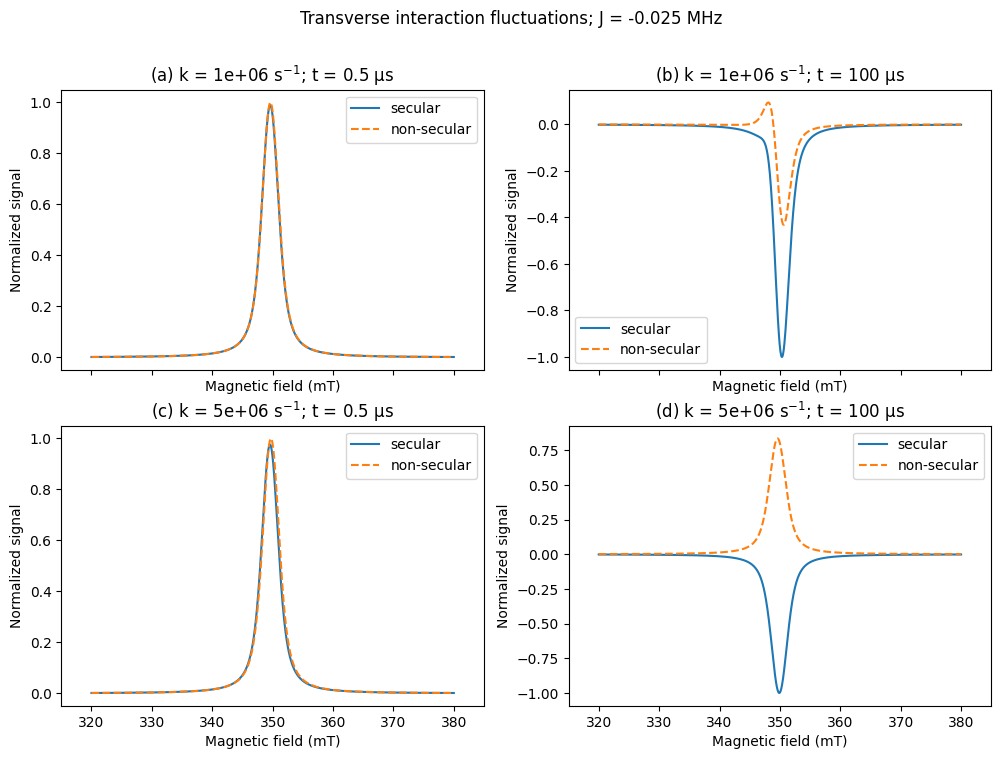

k=1e+06 s^-1, t=0.5 μs: max |nonsec-sec| / max |sec| = 2.18%
k=1e+06 s^-1, t=100 μs: max |nonsec-sec| / max |sec| = 60.9%
k=5e+06 s^-1, t=0.5 μs: max |nonsec-sec| / max |sec| = 8.35%
k=5e+06 s^-1, t=100 μs: max |nonsec-sec| / max |sec| = 182%


In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
labels = ['(a)', '(b)', '(c)', '(d)']
for i, k in enumerate(k_values_6):
    sec = results_6[k, True].numpy()
    full = results_6[k, False].numpy()
    for j, time in enumerate(times_6):
        ax = axes[i, j]
        scale = max(np.max(np.abs(sec[j])), np.max(np.abs(full[j])))
        ax.plot(fields_6.cpu().numpy()*1e3, sec[j]/scale, label='secular')
        ax.plot(fields_6.cpu().numpy()*1e3, full[j]/scale, '--', label='non-secular')
        ax.set_title(f'{labels[2*i+j]} k = {k:.0e} s$^{{-1}}$; t = {time.item()*1e6:g} μs')
        ax.set_xlabel('Magnetic field (mT)')
        ax.set_ylabel('Normalized signal')
        ax.set_xlim(315, 385)
        ax.legend()
fig.suptitle(f'Transverse interaction fluctuations; J = {-J_6/2e6:g} MHz')
plt.savefig("nonsecular_relaxation.eps")
plt.show()

for k in k_values_6:
    full, sec = results_6[k, False], results_6[k, True]
    for j, time in enumerate(times_6):
        difference = (full[j]-sec[j]).abs().max()/sec[j].abs().max()
        print(f'k={k:.0e} s^-1, t={time.item()*1e6:g} μs: '
              f'max |nonsec-sec| / max |sec| = {100*difference.item():.3g}%')

**Figure S10.** Time-resolved EPR spectra of the triplet–doublet model considered in Sec. V.4, using the Hamiltonian and relaxation parameters defined above. Panels (a) and (b) show $k=10^6\;\mathrm{s}^{-1}$ at 0.5 and 100 μs, respectively; (c) and (d) show $k=5\times10^6\;\mathrm{s}^{-1}$ at the same delays. Solid and dashed curves show secular and non-secular additional relaxation. Both curves share one normalization factor within each panel. The results show pronounced intensity differences between secular and non-secular relaxation at 100 μs.

## 6.1. Resonance-shift criterion

Let $E_a$ be the Hamiltonian eigenenergies in Hz and $R_{abcd}$ the total relaxation-superoperator elements, where $a,b,c,d$ label eigenstates. Define

$$\lambda_{ab}^{(0)}=R_{abab}-2\pi i(E_a-E_b),\qquad
\Delta_{ab}=R_{abab}+\sum_{(c,d)\ne(a,b)}
\frac{R_{abcd}R_{cdab}}{\lambda_{ab}^{(0)}-\lambda_{cd}^{(0)}}.$$

Here $\lambda_{ab}^{(0)}$ is the diagonal Liouvillian mode and $\Delta_{ab}$ its relaxation correction. The resonance shift, transverse relaxation time and homogeneous Lorentzian FWHM are

$$\delta\nu_{ab}=-\frac{\operatorname{Im}\Delta_{ab}}{2\pi},\qquad
T_{2,ab}^{-1}=-\operatorname{Re}\Delta_{ab},\qquad
\Gamma_{ab}=\frac{1}{\pi T_{2,ab}}.$$

The criterion is $\eta_{ab}=|\delta\nu_{ab}|/\Gamma_{ab}\ll1$. Sample broadening is excluded from $\Gamma_{ab}$. We use the supplied function unchanged, with its original validity cutoff, and require $\max\eta_{ab}<10^{-2}$.

In [33]:
from mars.population.resonance_line_shift import resonance_shift_criterion

## 6.2. Mean and maximum on the existing MaRs mesh

The function is evaluated at the resonance fields already obtained by MaRs for each orientation. The table reports unweighted means and maxima of the coefficients; invalid entries are not discarded.

In [34]:
from mars.population import PropagatorDensityPopulator
from mars.population.tr_utils import EvolutionSuper


class ShiftPopulator(PropagatorDensityPopulator):
    def _compute_out(self, time, res_fields, lvl_down, lvl_up, energies,
                     vector_down, vector_up, full_system_vectors, initial_density,
                     Gx, Gy, Sz_eigen, Sz_prod, resonance_frequency, H0,
                     *args, **kwargs):
        generator = self._init_tr_matrix_generator(
            time, res_fields, lvl_down, lvl_up, energies, vector_down, vector_up,
            full_system_vectors, resonance_frequency, H0, *args, **kwargs
        )
        temp, H, thermal, driven = generator(time)
        R = EvolutionSuper(energies)(temp, torch.zeros_like(H), thermal, driven)
        coefficients = []
        for index in self.resonance_entries.nonzero().tolist():
            index = tuple(index)
            line = index[-1]
            result = resonance_shift_criterion(
                R[index], energies[index], [lvl_down[line]], [lvl_up[line]])[0]
            coefficients.append(result["criterion"])
        return res_fields.new_tensor(coefficients)


class ShiftSpectra(spectra_manager.DensityTimeSpectra):
    def _postcompute_batch_data(self, sample, res_fields, *args, **kwargs):
        self.intensity_calculator.populator.resonance_entries = torch.isfinite(res_fields)
        return super()._postcompute_batch_data(sample, res_fields, *args, **kwargs)

    def _finalize(self, res_fields, coefficients, *args, **kwargs):
        return dict(mean=coefficients.mean().item(), maximum=coefficients.max().item())

In [35]:
shift_summary = {}
populator = ShiftPopulator(init_temperature=temperature, dtype=dtype, device=device)
manager = ShiftSpectra(
    freq=freq_res, sample=sample_6, populator=populator,
    temperature=temperature, hamiltonian_mode="direct",
    recompute_spin_parameters=False, dtype=dtype, device=device
)
print("k (s^-1) | relaxation | mean criterion | max criterion | test")
for k in k_values_6:
    for secular in (True, False):
        context = get_extra_context(base_context_6, sample_6, k, secular)
        context.close_context()
        manager.update_context(context)
        summary = manager(sample_6, fields_6, times_6[:1])
        shift_summary[k, secular] = summary
        passed = summary["maximum"] < 1e-2
        label = "secular" if secular else "non-secular"
        status = "PASS" if passed else "FAIL"
        print(f"{k:.0e} | {label} | {summary["mean"]:.6g} | {summary["maximum"]:.6g} | {status}")
        assert passed, f"Shift test failed: k={k:g}, secular={secular}"

k (s^-1) | relaxation | mean criterion | max criterion | test
1e+06 | secular | 5.98665e-07 | 1.11455e-06 | PASS
1e+06 | non-secular | 0.000155168 | 0.000511531 | PASS
5e+06 | secular | 2.55837e-07 | 4.77066e-07 | PASS
5e+06 | non-secular | 0.00145231 | 0.00710383 | PASS
